## Imports e Configuração do Dispositivo (GPU/CPU)

In [1]:
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
import pandas as pd
import numpy as np
import re
from collections import Counter
import matplotlib.pyplot as plt
import sys
import pickle

# Importar o modelo criado em src/pytorch_models.py
sys.path.append('../src')
from pytorch_models import TextBiLSTM

# Configuração de dispositivo (GPU se disponível)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"A usar o dispositivo: {device}")

# Seed para reprodutibilidade
torch.manual_seed(42)
np.random.seed(42)

A usar o dispositivo: cpu


## Construção do Vocabulário e Dataset PyTorch

In [2]:
def tokenize(text):
    text = str(text).lower()
    return re.findall(r'\b[a-z]{2,}\b', text)

class Vocabulary:
    def __init__(self, max_size=10000, unk_token="<UNK>", pad_token="<PAD>"):
        self.max_size = max_size
        self.pad_token = pad_token
        self.unk_token = unk_token
        self.w2i = {pad_token: 0, unk_token: 1}
        self.i2w = {0: pad_token, 1: unk_token}

    def build_vocab(self, texts):
        counter = Counter()
        for text in texts:
            counter.update(tokenize(text))
        
        most_common = counter.most_common(self.max_size - 2)
        for word, _ in most_common:
            idx = len(self.w2i)
            self.w2i[word] = idx
            self.i2w[idx] = word

    def encode(self, text, max_len=128):
        tokens = tokenize(text)
        ids = [self.w2i.get(token, self.w2i[self.unk_token]) for token in tokens[:max_len]]
        # Padding
        if len(ids) < max_len:
            ids += [self.w2i[self.pad_token]] * (max_len - len(ids))
        return ids

class TextDataset(Dataset):
    def __init__(self, texts, labels, vocab, max_len=128):
        self.texts = texts
        self.labels = labels
        self.vocab = vocab
        self.max_len = max_len

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, idx):
        encoded = self.vocab.encode(self.texts[idx], max_len=self.max_len)
        label = self.labels[idx]
        return torch.tensor(encoded, dtype=torch.long), torch.tensor(label, dtype=torch.float32)

## Carregamento dos Dados e DataLoaders

In [3]:
import pandas as pd
import numpy as np
import torch
from torch.utils.data import DataLoader

# Carregar o dataset
df = pd.read_csv('../data/processed/full_dataset_updated.csv')
df = df.sample(frac=1, random_state=42).reset_index(drop=True)

texts = df['text'].values
labels = df['label'].values

# Split (80% Treino, 10% Validação, 10% Teste)
n = len(df)
train_end, val_end = int(n * 0.8), int(n * 0.9)

train_texts, train_labels = texts[:train_end], labels[:train_end]
val_texts, val_labels = texts[train_end:val_end], labels[train_end:val_end]
test_texts, test_labels = texts[val_end:], labels[val_end:]

# Mapeamento de rótulos de texto para inteiros (0 e 1)
label_map = {'human': 0, 'chatgpt': 1, 'AI': 1, 'Human': 0}

train_labels_clean = [label_map.get(val, val) for val in train_labels]
val_labels_clean   = [label_map.get(val, val) for val in val_labels]
test_labels_clean  = [label_map.get(val, val) for val in test_labels]

# Construir vocabulário no treino
vocab = Vocabulary(max_size=10000)
vocab.build_vocab(train_texts)

# Criar Datasets e DataLoaders com os rótulos limpos (numéricos)
max_sequence_len = 128
batch_size = 32

train_ds = TextDataset(train_texts, train_labels_clean, vocab, max_len=max_sequence_len)
val_ds   = TextDataset(val_texts,   val_labels_clean,   vocab, max_len=max_sequence_len)
test_ds  = TextDataset(test_texts,  test_labels_clean,  vocab, max_len=max_sequence_len)

train_loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True)
val_loader   = DataLoader(val_ds,   batch_size=batch_size, shuffle=False)
test_loader  = DataLoader(test_ds,  batch_size=batch_size, shuffle=False)

## Funções de Treino, Validação e Métricas

In [4]:
def compute_metrics(y_true, y_pred_prob):
    y_pred = (y_pred_prob >= 0.5).astype(int)
    tp = np.sum((y_pred == 1) & (y_true == 1))
    tn = np.sum((y_pred == 0) & (y_true == 0))
    fp = np.sum((y_pred == 1) & (y_true == 0))
    fn = np.sum((y_pred == 0) & (y_true == 1))
    
    acc = (tp + tn) / len(y_true) if len(y_true) > 0 else 0
    prec = tp / (tp + fp) if (tp + fp) > 0 else 0
    rec = tp / (tp + fn) if (tp + fn) > 0 else 0
    f1 = 2 * (prec * rec) / (prec + rec) if (prec + rec) > 0 else 0
    return acc, prec, rec, f1

def train_epoch(model, dataloader, criterion, optimizer, device):
    model.train()
    total_loss = 0
    for x_batch, y_batch in dataloader:
        x_batch, y_batch = x_batch.to(device), y_batch.to(device)
        optimizer.zero_grad()
        out = model(x_batch).squeeze(-1)
        loss = criterion(out, y_batch)
        loss.backward()
        optimizer.step()
        total_loss += loss.item()
    return total_loss / len(dataloader)

def evaluate(model, dataloader, criterion, device):
    model.eval()
    total_loss = 0
    all_preds, all_labels = [], []
    with torch.no_grad():
        for x_batch, y_batch in dataloader:
            x_batch, y_batch = x_batch.to(device), y_batch.to(device)
            out = model(x_batch).squeeze(-1)
            loss = criterion(out, y_batch)
            total_loss += loss.item()
            
            probs = torch.sigmoid(out).cpu().numpy()
            all_preds.extend(probs)
            all_labels.extend(y_batch.cpu().numpy())
            
    acc, prec, rec, f1 = compute_metrics(np.array(all_labels), np.array(all_preds))
    return total_loss / len(dataloader), acc, prec, rec, f1

## Inicialização e Treino do Modelo BiLSTM

In [5]:
# Hiperparâmetros
vocab_size = len(vocab.w2i)
embedding_dim = 128
hidden_dim = 128
epochs = 10
lr = 0.001

model = TextBiLSTM(vocab_size=vocab_size, embedding_dim=embedding_dim, hidden_dim=hidden_dim, n_layers=2, dropout=0.3).to(device)
criterion = nn.BCEWithLogitsLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=lr)

train_losses, val_losses = [], []

print("--- A INICIAR TREINO DA BILSTM EM PYTORCH ---")
for epoch in range(1, epochs + 1):
    tr_loss = train_epoch(model, train_loader, criterion, optimizer, device)
    val_loss, val_acc, val_prec, val_rec, val_f1 = evaluate(model, val_loader, criterion, device)
    
    train_losses.append(tr_loss)
    val_losses.append(val_loss)
    
    print(f"Epoch {epoch:02d}/{epochs:02d} | Train Loss: {tr_loss:.4f} | Val Loss: {val_loss:.4f} | Val Acc: {val_acc:.4f} | Val F1: {val_f1:.4f}")

--- A INICIAR TREINO DA BILSTM EM PYTORCH ---
Epoch 01/10 | Train Loss: 0.3323 | Val Loss: 0.0178 | Val Acc: 1.0000 | Val F1: 1.0000
Epoch 02/10 | Train Loss: 0.0134 | Val Loss: 0.0021 | Val Acc: 1.0000 | Val F1: 1.0000
Epoch 03/10 | Train Loss: 0.0063 | Val Loss: 0.0012 | Val Acc: 1.0000 | Val F1: 1.0000
Epoch 04/10 | Train Loss: 0.0051 | Val Loss: 0.0006 | Val Acc: 1.0000 | Val F1: 1.0000
Epoch 05/10 | Train Loss: 0.0007 | Val Loss: 0.0004 | Val Acc: 1.0000 | Val F1: 1.0000
Epoch 06/10 | Train Loss: 0.0005 | Val Loss: 0.0003 | Val Acc: 1.0000 | Val F1: 1.0000
Epoch 07/10 | Train Loss: 0.0003 | Val Loss: 0.0002 | Val Acc: 1.0000 | Val F1: 1.0000
Epoch 08/10 | Train Loss: 0.0003 | Val Loss: 0.0001 | Val Acc: 1.0000 | Val F1: 1.0000
Epoch 09/10 | Train Loss: 0.0002 | Val Loss: 0.0001 | Val Acc: 1.0000 | Val F1: 1.0000
Epoch 10/10 | Train Loss: 0.0002 | Val Loss: 0.0001 | Val Acc: 1.0000 | Val F1: 1.0000


## Gráfico das Curvas de Perda (Loss)

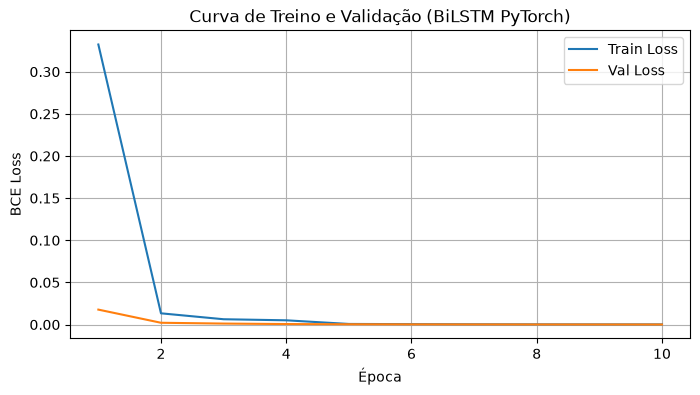

In [6]:
plt.figure(figsize=(8, 4))
plt.plot(range(1, epochs + 1), train_losses, label='Train Loss')
plt.plot(range(1, epochs + 1), val_losses, label='Val Loss')
plt.xlabel('Época')
plt.ylabel('BCE Loss')
plt.title('Curva de Treino e Validação (BiLSTM PyTorch)')
plt.legend()
plt.grid(True)
plt.show()

## Avaliação Final no Conjunto de Teste

In [7]:
test_loss, test_acc, test_prec, test_rec, test_f1 = evaluate(model, test_loader, criterion, device)

print("=== RESULTADOS NO CONJUNTO DE TESTE (BiLSTM) ===")
print(f"Accuracy:  {test_acc:.4f}")
print(f"Precision: {test_prec:.4f}")
print(f"Recall:    {test_rec:.4f}")
print(f"F1-Score:  {test_f1:.4f}")

=== RESULTADOS NO CONJUNTO DE TESTE (BiLSTM) ===
Accuracy:  1.0000
Precision: 1.0000
Recall:    1.0000
F1-Score:  1.0000


## Guardar o Modelo e o Vocabulário para Submissão

In [15]:
# Guardar o dicionário com o modelo, vocabulário e hiperparâmetros
checkpoint = {
    'model_state_dict': model.state_dict(),
    'vocab_w2i': vocab.w2i,
    'max_len': max_sequence_len,
    'vocab_size': vocab_size,
    'embedding_dim': embedding_dim,
    'hidden_dim': hidden_dim
}

torch.save(checkpoint, '../models/pytorch_bilstm.pth')
print("Modelo PyTorch gravado com sucesso em '../models/pytorch_bilstm.pth'!")

Modelo PyTorch gravado com sucesso em '../models/pytorch_bilstm.pth'!
